# LAB 11 — Artificial Neural Networks: The Perceptron
## Student Information
- **Name:** Abdul Sami
- **Roll No:** 023-24-0211
- **Section:** G
- **Date:** 17 November 2026

**Dataset:** Iris (sklearn built-in) · Use `random_state=42` everywhere · Write a 1–2 sentence interpretation under every plot and table.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_classification
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

np.random.seed(42)
iris = load_iris()
print("Iris loaded:", iris.data.shape, "| Classes:", iris.target_names)

Iris loaded: (150, 4) | Classes: ['setosa' 'versicolor' 'virginica']


## Part 1 — The Neuron From Scratch

### Task 1.1 — Weighted sum, step function and predict
Write `weighted_sum`, `step_function`, `predict`. Verify slide 16 (`predict([0.6,0.8],[2,3],-2)` → 1) and slide 17 (w=[1,−0.5], b=0.5; inputs [1,1],[2,1],[0,3] → 1, 1, 0).

In [2]:
# Task 1.1
def weighted_sum(w, x, b):
    return np.dot(w, x) + b

def step_function(z):
    return 1 if z >= 0 else 0

def predict(w, x, b):
    return step_function(weighted_sum(w, x, b))

# Slide 16 check
print("Slide 16: predict([0.6,0.8],[2,3],-2) =", predict([0.6, 0.8], [2, 3], -2), "(expected 1)")

# Slide 17 check
w, b = [1, -0.5], 0.5
for x, exp in zip([[1, 1], [2, 1], [0, 3]], [1, 1, 0]):
    print(f"Slide 17: x={x}  z={weighted_sum(w, x, b):.2f}  y_hat={predict(w, x, b)}  (expected {exp})")


Slide 16: predict([0.6,0.8],[2,3],-2) = 1 (expected 1)
Slide 17: x=[1, 1]  z=1.00  y_hat=1  (expected 1)
Slide 17: x=[2, 1]  z=2.00  y_hat=1  (expected 1)
Slide 17: x=[0, 3]  z=-1.00  y_hat=0  (expected 0)


### Task 1.2 — One full epoch on the AND gate, by hand
AND: (0,0,0), (0,1,0), (1,0,0), (1,1,1). Start w=[0.2, −0.1], b=0, η=0.1. Print z, ŷ, e and the new w, b for each row; then the mistake count and "Converged!" / "Keep training.".

In [3]:
# Task 1.2
data = [(0, 0, 0), (0, 1, 0), (1, 0, 0), (1, 1, 1)]   # AND gate (x1, x2, y)
w = np.array([0.2, -0.1]); b = 0.0; eta = 0.1
mistakes = 0

for x1, x2, y in data:
    x = np.array([x1, x2])
    z = weighted_sum(w, x, b)
    y_hat = step_function(z)
    e = y - y_hat
    if e != 0:
        mistakes += 1
        w = w + eta * e * x
        b = b + eta * e
    print(f"x=({x1},{x2}) y={y} | z={z:+.2f} y_hat={y_hat} e={e:+d} | new w={np.round(w, 2)}, b={b:+.2f}")

print(f"\nFinal w = {np.round(w, 2)}, b = {b:.2f}, mistakes = {mistakes}")
print("Converged!" if mistakes == 0 else "Keep training.")


x=(0,0) y=0 | z=+0.00 y_hat=1 e=-1 | new w=[ 0.2 -0.1], b=-0.10
x=(0,1) y=0 | z=-0.20 y_hat=0 e=+0 | new w=[ 0.2 -0.1], b=-0.10
x=(1,0) y=0 | z=+0.10 y_hat=1 e=-1 | new w=[ 0.1 -0.1], b=-0.20
x=(1,1) y=1 | z=-0.20 y_hat=0 e=+1 | new w=[0.2 0. ], b=-0.10

Final w = [0.2 0. ], b = -0.10, mistakes = 3
Keep training.


## Part 2 — Train a Perceptron From Scratch

### Task 2.1 — Implement `train_perceptron`
`train_perceptron(X, y, eta=0.1, max_epochs=100)`: start from zeros, update on every mistake, record mistakes per epoch, stop after a zero-mistake epoch. Train on OR (y = [0,1,1,1]) and print w, b.

In [4]:
# Task 2.1
def train_perceptron(X, y, eta=0.1, max_epochs=100):
    X = np.asarray(X, dtype=float)
    w = np.zeros(X.shape[1]); b = 0.0
    mistakes = []
    for epoch in range(max_epochs):
        m = 0
        for xi, yi in zip(X, y):
            e = yi - predict(w, xi, b)
            if e != 0:                      # update only on a mistake
                w = w + eta * e * xi
                b = b + eta * e
                m += 1
        mistakes.append(m)
        if m == 0:                          # a clean epoch -> converged
            break
    return w, b, mistakes

X_or = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_or = np.array([0, 1, 1, 1])
w_or, b_or, mist_or = train_perceptron(X_or, y_or, eta=0.1, max_epochs=100)
print("OR gate  ->  w =", np.round(w_or, 3), " b =", round(b_or, 3))
print("Mistakes per epoch:", mist_or)


OR gate  ->  w = [0.1 0.1]  b = -0.1
Mistakes per epoch: [2, 2, 1, 0]


### Task 2.2 — Plot mistakes per epoch
Title "Perceptron training on OR gate", axes "Epoch" / "Mistakes"; mark the final epoch with a red dot.

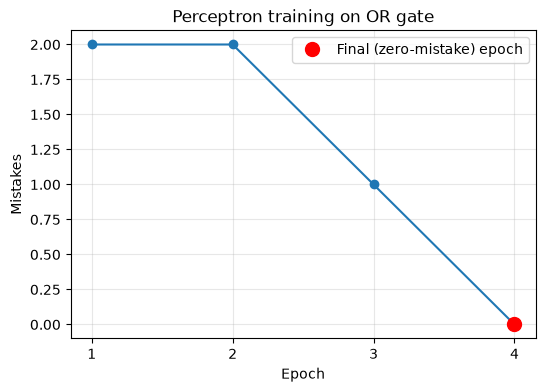

In [5]:
# Task 2.2
epochs = np.arange(1, len(mist_or) + 1)
plt.figure(figsize=(6, 4))
plt.plot(epochs, mist_or, marker="o", color="tab:blue")
plt.plot(epochs[-1], mist_or[-1], "ro", markersize=10, label="Final (zero-mistake) epoch")
plt.title("Perceptron training on OR gate")
plt.xlabel("Epoch"); plt.ylabel("Mistakes")
plt.xticks(epochs); plt.legend(); plt.grid(alpha=0.3)
plt.show()


**Interpretation:** The mistake count falls 2 → 2 → 1 → 0 and reaches zero at epoch 4, so the perceptron converged on OR (a linearly separable problem) and stopped immediately after the clean epoch (red dot).

## Part 3 — The Decision Boundary

### Task 3.1 — Plot the OR gate with its boundary
Boundary: x₂ = −(w₁/w₂)x₁ − b/w₂ over `np.linspace(-0.5, 1.5, 100)`. Class 0 blue circles, class 1 red squares, boundary black dashed. Write a reusable `plot_boundary(ax, w, b)` that handles w₂ = 0.

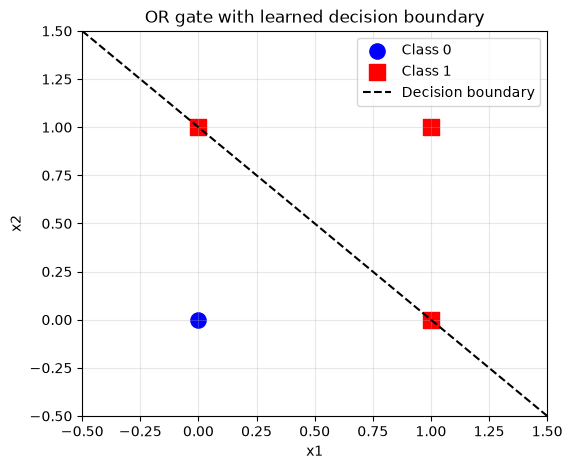

Boundary: 0.10*x1 + 0.10*x2 -0.10 = 0   (i.e. x1 + x2 = 1)


In [6]:
# Task 3.1
def plot_boundary(ax, w, b, xlim=(-0.5, 1.5), **kw):
    """Draw w1*x1 + w2*x2 + b = 0. Handles w2 = 0 (vertical line)."""
    style = dict(color="k", linestyle="--", label="Decision boundary"); style.update(kw)
    w1, w2 = w
    if not np.isclose(w2, 0):
        x1 = np.linspace(xlim[0], xlim[1], 100)
        ax.plot(x1, -(w1 / w2) * x1 - b / w2, **style)
    elif not np.isclose(w1, 0):
        ax.axvline(-b / w1, **style)         # vertical line x1 = -b/w1
    # (w1 = w2 = 0: no line to draw)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(*X_or[y_or == 0].T, c="blue", marker="o", s=120, label="Class 0")
ax.scatter(*X_or[y_or == 1].T, c="red", marker="s", s=120, label="Class 1")
plot_boundary(ax, w_or, b_or)
ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
ax.set_title("OR gate with learned decision boundary")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(); ax.grid(alpha=0.3)
plt.show()
print(f"Boundary: {w_or[0]:.2f}*x1 + {w_or[1]:.2f}*x2 {b_or:+.2f} = 0   (i.e. x1 + x2 = 1)")


**Interpretation:** The learned line is 0.1·x₁ + 0.1·x₂ − 0.1 = 0, i.e. x₁ + x₂ = 1; it is a straight line that isolates (0,0) from the other three points. ŷ = 1 on the upper-right side (where x₁ + x₂ ≥ 1, so z ≥ 0), and ŷ = 0 on the lower-left side that contains only (0,0).

### Task 3.2 — With and without bias
Train both versions on X=[[1,0],[0,1],[2,1],[1,2]], y=[0,0,1,1]; plot the two boundaries side by side. Did the no-bias version converge?

With bias   : w=[0.1 0.1], b=-0.20, epochs=4, final mistakes=0
Without bias: w=[0.1 0. ], b=0.00, epochs=100, final mistakes=2
No-bias converged? False


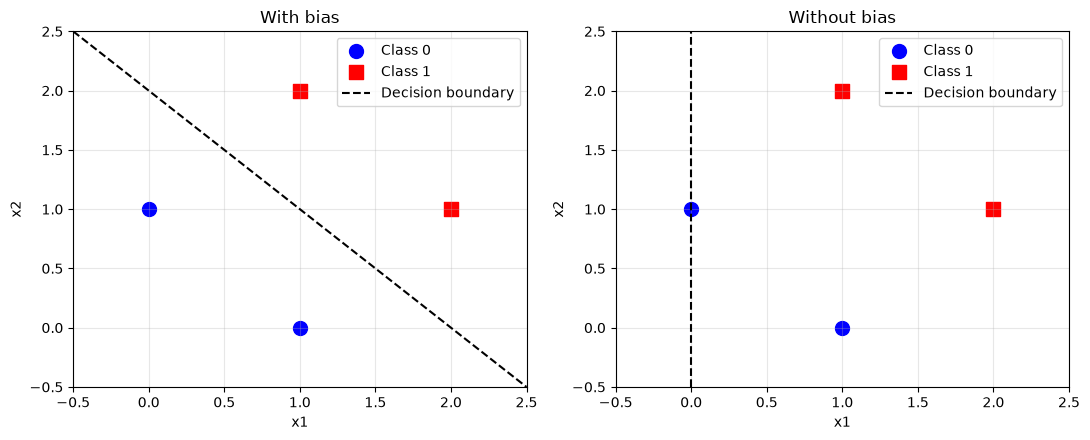

In [7]:
# Task 3.2
def train_perceptron_nobias(X, y, eta=0.1, max_epochs=100):
    X = np.asarray(X, dtype=float)
    w = np.zeros(X.shape[1]); b = 0.0        # b is never updated
    mistakes = []
    for epoch in range(max_epochs):
        m = 0
        for xi, yi in zip(X, y):
            e = yi - predict(w, xi, b)
            if e != 0:
                w = w + eta * e * xi
                m += 1
        mistakes.append(m)
        if m == 0:
            break
    return w, b, mistakes

X32 = np.array([[1, 0], [0, 1], [2, 1], [1, 2]]); y32 = np.array([0, 0, 1, 1])
w_b, b_b, m_b = train_perceptron(X32, y32)
w_n, b_n, m_n = train_perceptron_nobias(X32, y32)
print(f"With bias   : w={np.round(w_b,2)}, b={b_b:.2f}, epochs={len(m_b)}, final mistakes={m_b[-1]}")
print(f"Without bias: w={np.round(w_n,2)}, b={b_n:.2f}, epochs={len(m_n)}, final mistakes={m_n[-1]}")
print("No-bias converged?", m_n[-1] == 0)

plt.figure(figsize=(11, 4.5))
for k, (w_, b_, t) in enumerate([(w_b, b_b, "With bias"), (w_n, b_n, "Without bias")], 1):
    ax = plt.subplot(1, 2, k)
    ax.scatter(*X32[y32 == 0].T, c="blue", marker="o", s=100, label="Class 0")
    ax.scatter(*X32[y32 == 1].T, c="red", marker="s", s=100, label="Class 1")
    plot_boundary(ax, w_, b_, xlim=(-0.5, 2.5))
    ax.set_xlim(-0.5, 2.5); ax.set_ylim(-0.5, 2.5)
    ax.set_title(t); ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


**Interpretation:** With bias the perceptron converged in 4 epochs (w = [0.1, 0.1], b = −0.2) and the line separates the classes; without bias it did **not** converge (still 2 mistakes after 100 epochs) because the boundary is forced through the origin. Class 0 needs w₁ < 0 and w₂ < 0 while (2,1) needs 2w₁ + w₂ ≥ 0, which is impossible — the bias is what lets the line shift away from the origin (slide 19).

## Part 4 — The XOR Limitation

### Task 4.1 — Watch the perceptron fail
XOR: y = [0,1,1,0], `max_epochs=100`. Print final mistakes, w, b; plot mistakes per epoch and the boundary.

Epochs run: 100 | Final mistakes: 4 | Min mistakes in any epoch: 3
w = [-0.1  0. ]  b = 0.0


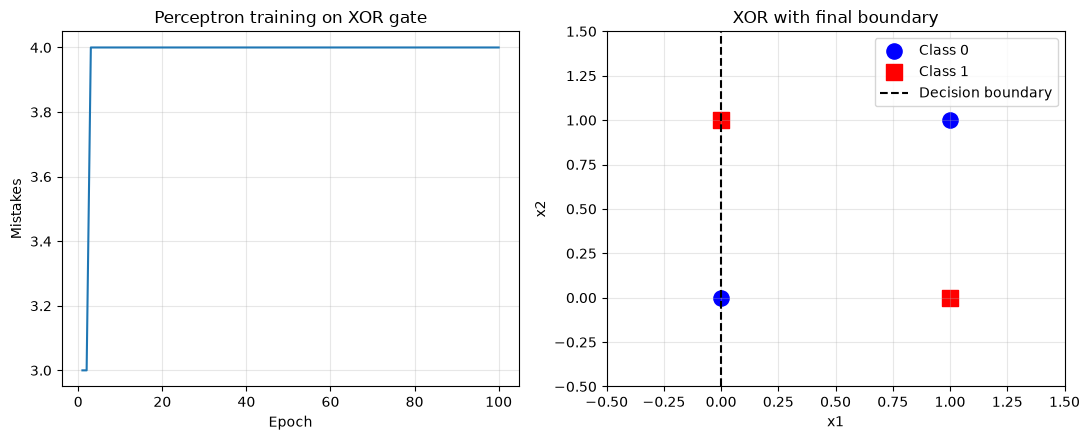

In [8]:
# Task 4.1
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]); y_xor = np.array([0, 1, 1, 0])
w_x, b_x, m_x = train_perceptron(X_xor, y_xor, eta=0.1, max_epochs=100)
print("Epochs run:", len(m_x), "| Final mistakes:", m_x[-1], "| Min mistakes in any epoch:", min(m_x))
print("w =", np.round(w_x, 3), " b =", round(b_x, 3))

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
axs[0].plot(range(1, len(m_x) + 1), m_x, color="tab:blue")
axs[0].set_title("Perceptron training on XOR gate"); axs[0].set_xlabel("Epoch"); axs[0].set_ylabel("Mistakes")
axs[0].grid(alpha=0.3)

axs[1].scatter(*X_xor[y_xor == 0].T, c="blue", marker="o", s=120, label="Class 0")
axs[1].scatter(*X_xor[y_xor == 1].T, c="red", marker="s", s=120, label="Class 1")
plot_boundary(axs[1], w_x, b_x)
axs[1].set_xlim(-0.5, 1.5); axs[1].set_ylim(-0.5, 1.5)
axs[1].set_title("XOR with final boundary"); axs[1].set_xlabel("x1"); axs[1].set_ylabel("x2")
axs[1].legend(); axs[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()


**Interpretation:** The perceptron never reaches zero mistakes: after 100 epochs it still makes 4 mistakes per epoch (the best epoch was 3) and the weights just oscillate (final w = [−0.1, 0], b = 0). XOR is not linearly separable — (0,0),(1,1) are on one diagonal and (0,1),(1,0) on the other — so no straight line can split them and the perceptron convergence theorem does not apply.

### Task 4.2 — Confirm no weight vector works
`check_xor(w, b)` returns True only if all four XOR constraints hold. Test 10,000 random (w₁, w₂, b) in [−5, 5].

In [9]:
# Task 4.2
def check_xor(w, b):
    return (np.dot(w, [0, 0]) + b < 0 and
            np.dot(w, [0, 1]) + b >= 0 and
            np.dot(w, [1, 0]) + b >= 0 and
            np.dot(w, [1, 1]) + b < 0)

np.random.seed(42)
W = np.random.uniform(-5, 5, (10000, 2))
B = np.random.uniform(-5, 5, 10000)
passing = [(W[i, 0], W[i, 1], B[i]) for i in range(10000) if check_xor(W[i], B[i])]
print("Triples tested :", 10000)
print("Triples passing:", len(passing))
print("No solution found" if len(passing) == 0 else f"First passing triple: {passing[0]}")


Triples tested : 10000
Triples passing: 0
No solution found


## Part 5 — scikit-learn Perceptron on Iris

### Task 5.1 — Train and evaluate
Petal features (2, 3), Setosa vs rest; 70/30 stratified split; `Perceptron(random_state=42)`. Print accuracy, confusion matrix, report, `coef_`, `intercept_`.

In [10]:
# Task 5.1
X5 = iris.data[:, (2, 3)]
y5 = (iris.target == 0).astype(int)
X5_tr, X5_te, y5_tr, y5_te = train_test_split(X5, y5, test_size=0.3, random_state=42, stratify=y5)

clf = Perceptron(random_state=42)
clf.fit(X5_tr, y5_tr)
pred5 = clf.predict(X5_te)

print("Accuracy:", accuracy_score(y5_te, pred5))
print("\nConfusion matrix:\n", confusion_matrix(y5_te, pred5))
print("\nClassification report:\n", classification_report(y5_te, pred5, target_names=["Rest", "Setosa"]))
print("coef_     :", clf.coef_)
print("intercept_:", clf.intercept_)


Accuracy: 1.0

Confusion matrix:
 [[30  0]
 [ 0 15]]

Classification report:
               precision    recall  f1-score   support

        Rest       1.00      1.00      1.00        30
      Setosa       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

coef_     : [[-1.3 -2.2]]
intercept_: [4.]


**Interpretation:** Accuracy is 1.00 with a confusion matrix of [[30, 0], [0, 15]], so Setosa is perfectly separated from the rest using petal length and width. `coef_` = [−1.3, −2.2] is the weight vector w = (w₁, w₂) and `intercept_` = 4.0 is the bias b from Part 1.

### Task 5.2 — Visualise the learned boundary
Boundary from `coef_[0]`, `intercept_[0]`; test set coloured by class; misclassified points as red ×.

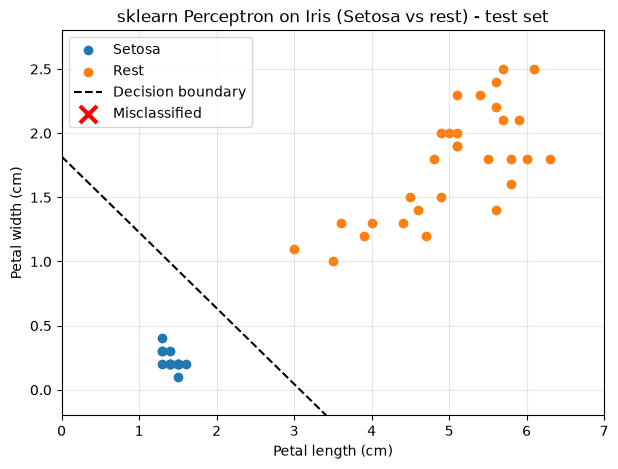

Misclassified test points: 0 of 45


In [11]:
# Task 5.2
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(*X5_te[y5_te == 1].T, c="tab:blue", label="Setosa")
ax.scatter(*X5_te[y5_te == 0].T, c="tab:orange", label="Rest")
plot_boundary(ax, clf.coef_[0], clf.intercept_[0], xlim=(0, 7))
wrong = pred5 != y5_te
ax.scatter(*X5_te[wrong].T, c="red", marker="x", s=150, linewidths=3, label="Misclassified", zorder=5)
ax.set_xlim(0, 7); ax.set_ylim(-0.2, 2.8)
ax.set_title("sklearn Perceptron on Iris (Setosa vs rest) - test set")
ax.set_xlabel("Petal length (cm)"); ax.set_ylabel("Petal width (cm)")
ax.legend(); ax.grid(alpha=0.3)
plt.show()
print("Misclassified test points:", int(wrong.sum()), "of", len(y5_te))


**Interpretation:** 0 of 45 test points are misclassified, so no red × appears. The boundary is a straight line (−1.3·x₁ − 2.2·x₂ + 4 = 0) because it is the set where the linear function z = w·x + b equals zero.

### Task 5.3 — Effect of learning rate
`eta0` = 0.001, 0.1, 10.0. Table of eta0 | accuracy | `n_iter_` | `coef_`. Do the predictions change? What does η do when training starts from w = 0?

In [12]:
# Task 5.3
results = []
preds = {}
print(f"{'eta0':>8} | {'accuracy':>8} | {'n_iter_':>7} | coef_")
print("-" * 60)
for eta0 in [0.001, 0.1, 10.0]:
    m = Perceptron(eta0=eta0, random_state=42).fit(X5_tr, y5_tr)
    p = m.predict(X5_te); preds[eta0] = p
    print(f"{eta0:>8} | {accuracy_score(y5_te, p):>8.4f} | {m.n_iter_:>7} | {np.round(m.coef_[0], 4)}")
    results.append(m.coef_[0])

print("\nPredictions identical across all eta0?",
      all(np.array_equal(preds[0.001], preds[k]) for k in preds))
print("coef_ ratios (w2/w1):", [round(c[1] / c[0], 4) for c in results])


    eta0 | accuracy | n_iter_ | coef_
------------------------------------------------------------
   0.001 |   1.0000 |       6 | [-0.0013 -0.0022]
     0.1 |   1.0000 |       7 | [-0.13 -0.22]
    10.0 |   1.0000 |       7 | [-13. -22.]

Predictions identical across all eta0? True
coef_ ratios (w2/w1): [np.float64(1.6923), np.float64(1.6923), np.float64(1.6923)]


**Interpretation:** The predictions do not change: accuracy is 1.00 for all three η₀ values. The coefficients are the same direction scaled by η (−0.0013/−0.0022, −0.13/−0.22, −13/−22; ratio w₂/w₁ = 1.69 in all cases). Starting from w = 0, every update is η·e·x, so η only multiplies w and b by a constant, which does not change the sign of z and hence not the boundary; the small n_iter_ difference (6 vs 7) comes from the loss-based stopping tolerance, whose scale depends on η.

## Part 6 — Multi-Class Classification

### Task 6.1 — All three Iris classes
All four features, `y = iris.target`, 70/30 stratified; `Perceptron(random_state=42, max_iter=1000)`. Print report, confusion matrix, `coef_.shape`. Which class is hardest?

In [13]:
# Task 6.1
X6, y6 = iris.data, iris.target
X6_tr, X6_te, y6_tr, y6_te = train_test_split(X6, y6, test_size=0.3, random_state=42, stratify=y6)
clf6 = Perceptron(random_state=42, max_iter=1000).fit(X6_tr, y6_tr)
pred6 = clf6.predict(X6_te)

print("Classification report:\n", classification_report(y6_te, pred6, target_names=iris.target_names, zero_division=0))
print("Confusion matrix:\n", confusion_matrix(y6_te, pred6))
print("coef_.shape:", clf6.coef_.shape)


Classification report:
               precision    recall  f1-score   support

      setosa       0.52      1.00      0.68        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.67        45
   macro avg       0.48      0.67      0.55        45
weighted avg       0.48      0.67      0.55        45

Confusion matrix:
 [[15  0  0]
 [14  0  1]
 [ 0  0 15]]
coef_.shape: (3, 4)


**Interpretation:** The accuracy is only 0.67 (macro-F1 0.55). Versicolor is the hardest class: recall is 0.00, with 14 of its 15 test flowers predicted as Setosa and 1 as Virginica, because versicolor sits between the other two classes so a single straight line (one-vs-rest) cannot isolate it. `coef_.shape` = (3, 4): each row is the weight vector of one one-vs-rest perceptron (one per class), with one weight per feature.

### Task 6.2 — Perceptron vs Logistic Regression
`LogisticRegression(random_state=42, max_iter=200)` on the same split; side-by-side accuracy and macro-F1; why can it win (slide 32)?

In [14]:
# Task 6.2
lr = LogisticRegression(random_state=42, max_iter=200).fit(X6_tr, y6_tr)
pred_lr = lr.predict(X6_te)

print(f"{'Model':<22}{'Accuracy':>10}{'Macro-F1':>10}")
print("-" * 42)
print(f"{'Perceptron':<22}{accuracy_score(y6_te, pred6):>10.4f}{f1_score(y6_te, pred6, average='macro'):>10.4f}")
print(f"{'Logistic Regression':<22}{accuracy_score(y6_te, pred_lr):>10.4f}{f1_score(y6_te, pred_lr, average='macro'):>10.4f}")
print("\nLogReg confusion matrix:\n", confusion_matrix(y6_te, pred_lr))


Model                   Accuracy  Macro-F1
------------------------------------------
Perceptron                0.6667    0.5499
Logistic Regression       0.9333    0.9333

LogReg confusion matrix:
 [[15  0  0]
 [ 0 14  1]
 [ 0  2 13]]


**Interpretation:** Logistic Regression scores accuracy 0.933 and macro-F1 0.933 versus 0.667 and 0.550 for the Perceptron, a gain of about 27 points in accuracy. The sigmoid is smooth and gives a non-zero gradient for every sample, so logistic regression keeps improving on overlapping classes (versicolor/virginica), whereas the step function only says right or wrong and updates only on mistakes, so it never settles when the classes are not linearly separable (slide 32).

## Part 7 — Graded Questions (5 marks)
Answer in the Markdown cells below, using your own numbers.

**Q1 [0.5 marks] — Manual update trace.** w = [0.5, −0.3], b = 0.2, η = 0.1, x = [1, 2], y = 0. Compute z and ŷ, then e, then the updated w₁, w₂ and b.

**Given:** w = [0.5, −0.3], b = 0.2, η = 0.1, x = [1, 2], y = 0

- z = w·x + b = (0.5)(1) + (−0.3)(2) + 0.2 = 0.5 − 0.6 + 0.2 = **0.1**
- ŷ = step(0.1) = **1** (since z ≥ 0), but the target is y = 0 → a mistake
- e = y − ŷ = 0 − 1 = **−1**
- w₁ = 0.5 + 0.1(−1)(1) = **0.4**
- w₂ = −0.3 + 0.1(−1)(2) = −0.3 − 0.2 = **−0.5**
- b = 0.2 + 0.1(−1) = **0.1**

Updated parameters: w = [0.4, −0.5], b = 0.1. Check: new z = 0.4 − 1.0 + 0.1 = −0.5 < 0 → ŷ = 0, now correct.

**Q2 [0.5 marks] — Boundary geometry.** After training on AND: w = [0.3, 0.2], b = −0.4. Write the boundary equation. Which side is (1, 1) on, and what is ŷ?

**Boundary:** set z = 0 → 0.3x₁ + 0.2x₂ − 0.4 = 0 → x₂ = −(0.3/0.2)x₁ + 0.4/0.2 = **x₂ = −1.5x₁ + 2**.

**Point (1, 1):** z = 0.3 + 0.2 − 0.4 = **0.1 ≥ 0**, so it lies on the positive (ŷ = 1) side, the upper-right side of the line (the line at x₁ = 1 has x₂ = 0.5, and the point has x₂ = 1 > 0.5). Therefore **ŷ = 1**, which matches AND(1,1) = 1. The other three AND inputs give z = −0.4, −0.2, −0.1 < 0, so ŷ = 0 as required.

**Q3 [1 mark] — XOR analysis.** (a) Show algebraically that the four XOR constraints cannot all hold. (b) Sketch XOR on x₁–x₂ axes (insert an image or a matplotlib plot) to show why no line separates it. (c) Name one architectural change that solves XOR.

**(a) Algebraic proof.** The four XOR constraints (step: ŷ = 1 iff z ≥ 0) are:

1. (0,0) → 0: b < 0
2. (0,1) → 1: w₂ + b ≥ 0
3. (1,0) → 1: w₁ + b ≥ 0
4. (1,1) → 0: w₁ + w₂ + b < 0

Adding (2) and (3): w₁ + w₂ + 2b ≥ 0, so w₁ + w₂ + b ≥ −b. From (1), b < 0, so −b > 0, hence w₁ + w₂ + b > 0. This contradicts (4), which needs w₁ + w₂ + b < 0. So no (w₁, w₂, b) can satisfy all four, which agrees with Task 4.2 (0 of 10,000 random triples passed).

**(b) Sketch.** See the plot below: the class-1 points (0,1) and (1,0) lie on one diagonal and the class-0 points (0,0) and (1,1) on the other, so any straight line that has the two class-1 points on one side must also put a class-0 point on that side (the segments joining same-class points cross).

**(c) Architectural fix.** Add a hidden layer (a multi-layer perceptron): for example, two hidden neurons computing OR and NAND, and an output neuron computing AND of the two, gives XOR = AND(OR(x₁,x₂), NAND(x₁,x₂)).

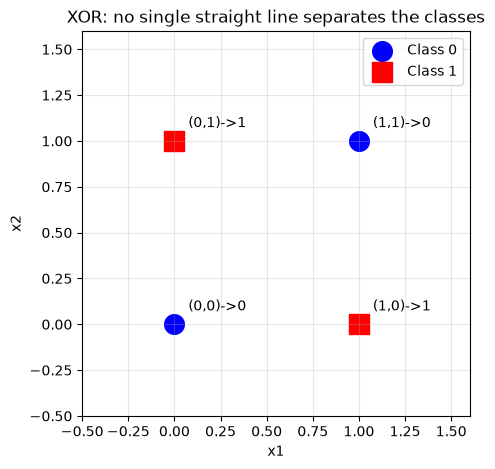

In [15]:
# Q3(b) - XOR sketch
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(*X_xor[y_xor == 0].T, c="blue", marker="o", s=200, label="Class 0")
ax.scatter(*X_xor[y_xor == 1].T, c="red", marker="s", s=200, label="Class 1")
for (x1, x2), yy in zip(X_xor, y_xor):
    ax.annotate(f"({x1},{x2})->{yy}", (x1, x2), textcoords="offset points", xytext=(10, 10))
ax.set_xlim(-0.5, 1.6); ax.set_ylim(-0.5, 1.6)
ax.set_title("XOR: no single straight line separates the classes")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(); ax.grid(alpha=0.3)
plt.show()


**Q4 [1.5 marks] — Iris extension.** Add sepal length (feature 0) so you use features (0, 2, 3). Retrain the Part 5 model; report accuracy and macro-F1. Does the extra feature help? Support your answer with numbers.

In [16]:
# Q4
def run_iris_binary(features):
    X = iris.data[:, features]; y = (iris.target == 0).astype(int)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
    c = Perceptron(random_state=42).fit(Xtr, ytr)
    p = c.predict(Xte)
    return accuracy_score(yte, p), f1_score(yte, p, average="macro"), c.n_iter_, int((p != yte).sum())

print(f"{'Features':<12}{'Accuracy':>10}{'Macro-F1':>10}{'n_iter_':>9}{'Errors':>8}")
print("-" * 49)
for name, f in [("(2, 3)", (2, 3)), ("(0, 2, 3)", (0, 2, 3))]:
    a, f1, it, err = run_iris_binary(f)
    print(f"{name:<12}{a:>10.4f}{f1:>10.4f}{it:>9}{err:>8}")


Features      Accuracy  Macro-F1  n_iter_  Errors
-------------------------------------------------
(2, 3)          1.0000    1.0000        7       0
(0, 2, 3)       1.0000    1.0000        7       0


**Results (features 0, 2, 3 vs baseline 2, 3, same split, random_state = 42):**

| Features | Accuracy | Macro-F1 | n_iter_ | Test errors |
|---|---|---|---|---|
| (2, 3) petals only | 1.0000 | 1.0000 | 7 | 0 |
| (0, 2, 3) + sepal length | 1.0000 | 1.0000 | 7 | 0 |

**Does the extra feature help? No.** Accuracy and macro-F1 are both already 1.00 with petal length and width alone, because Setosa is linearly separable from the other two species on the petal features, so there is no error left for sepal length to remove (change = +0.0000 in both metrics). The third feature only adds an extra weight to learn; it would matter only for a harder problem, such as versicolor vs virginica.

**Q5 [1.5 marks] — Synthetic data.** `make_classification(n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=42)`, 70/30 split. Train your hand-built perceptron and sklearn's. Compare accuracy, epochs, final w and b; plot both boundaries side by side.

               Test acc  Epochs   w                      b
Hand-built       0.8167     100   [ 0.307 -0.256]   0.200
sklearn          0.6667       6   [2.281 0.58 ]   2.000
Hand-built final-epoch mistakes: 33


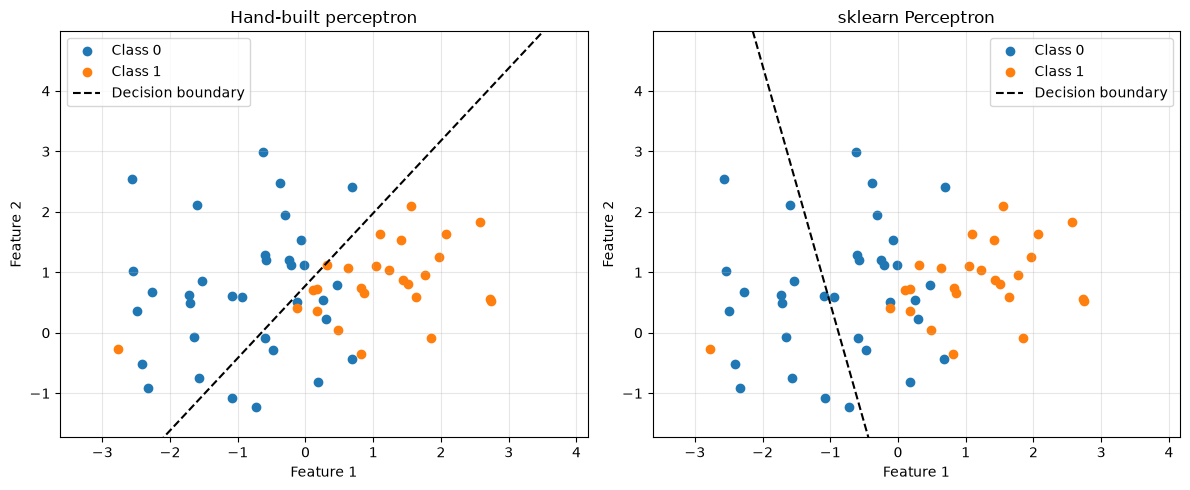

In [17]:
# Q5
Xs, ys = make_classification(n_samples=200, n_features=2, n_redundant=0,
                             n_clusters_per_class=1, random_state=42)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.3, random_state=42)

# hand-built perceptron
w_h, b_h, m_h = train_perceptron(Xs_tr, ys_tr, eta=0.1, max_epochs=100)
pred_h = np.array([predict(w_h, x, b_h) for x in Xs_te])

# sklearn perceptron
sk = Perceptron(random_state=42).fit(Xs_tr, ys_tr)
pred_sk = sk.predict(Xs_te)

print(f"{'':<14}{'Test acc':>9}{'Epochs':>8}   w                      b")
print(f"{'Hand-built':<14}{accuracy_score(ys_te, pred_h):>9.4f}{len(m_h):>8}   {np.round(w_h, 3)}   {b_h:.3f}")
print(f"{'sklearn':<14}{accuracy_score(ys_te, pred_sk):>9.4f}{sk.n_iter_:>8}   {np.round(sk.coef_[0], 3)}   {sk.intercept_[0]:.3f}")
print("Hand-built final-epoch mistakes:", m_h[-1])

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, (w_, b_, t) in zip(axs, [(w_h, b_h, "Hand-built perceptron"), (sk.coef_[0], sk.intercept_[0], "sklearn Perceptron")]):
    ax.scatter(*Xs_te[ys_te == 0].T, c="tab:blue", label="Class 0")
    ax.scatter(*Xs_te[ys_te == 1].T, c="tab:orange", label="Class 1")
    lo, hi = Xs[:, 0].min() - 0.5, Xs[:, 0].max() + 0.5
    plot_boundary(ax, w_, b_, xlim=(lo, hi))
    ax.set_xlim(lo, hi); ax.set_ylim(Xs[:, 1].min() - 0.5, Xs[:, 1].max() + 0.5)
    ax.set_title(t); ax.set_xlabel("Feature 1"); ax.set_ylabel("Feature 2"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


**Results (200 samples, 70/30 split, random_state = 42):**

| | Test accuracy | Epochs | w | b |
|---|---|---|---|---|
| Hand-built (η = 0.1, max 100 epochs) | 0.8167 | 100 (did not converge) | [0.307, −0.256] | 0.200 |
| sklearn `Perceptron` (η₀ = 1) | 0.6667 | 6 (`n_iter_`) | [2.281, 0.580] | 2.000 |

**Analysis.** The two clusters of this synthetic data overlap, so the data are **not linearly separable**: the hand-built perceptron never reached a zero-mistake epoch (33 mistakes on the 140 training points in its last epoch) and ran all 100 epochs, so the convergence theorem does not guarantee a solution. Both models return only the weights at the moment they stopped, and these keep jumping around on non-separable data, which explains why the two boundaries differ (different slope and position in the plots) even though the algorithm is the same. sklearn stopped after 6 epochs because its loss stopped improving (tolerance rule) and its weights are larger only because η₀ = 1 scales every update (η scales w and b but not the boundary); it also shuffles the data, and on this run its stopping point happened to be a worse boundary (0.667 vs 0.817). The ranking depends on where each run stops, so a single comparison should not be generalised; for overlapping classes a smoother model such as logistic regression is the better choice.